# 09 — Berka Exploration: AE Variants + Extra Clustering Models

**Dataset:** Track C (Berka) — project champion dataset  
**Goal:** Explore more autoencoder designs and alternative clustering heads without changing the registered champion until we decide to promote one.

**Registered champion (reference):** `c_ae_lat4_k6` = AE(latent=4) + K-Means k=6

This notebook mirrors `customer_segmentation.pipelines.run_berka_explore` with richer plots so you can inspect every family.

Related: `reports/berka_explore_findings.md`, `artifacts/experiments/berka_explore/`


## 0. Setup

In [1]:
import warnings
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import (
    AgglomerativeClustering, Birch, DBSCAN, HDBSCAN,
    KMeans, MiniBatchKMeans, SpectralClustering,
)
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

from customer_segmentation.features.build_berka_features import build_and_save_berka_features
from customer_segmentation.models.autoencoder import TORCH_OK, train_autoencoder
from customer_segmentation.models.metrics import evaluate_clustering, size_sanity

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
RANDOM_STATE = 42
K_FIXED = 6
np.random.seed(RANDOM_STATE)

OUT = ROOT / "artifacts" / "experiments" / "berka_explore"
OUT.mkdir(parents=True, exist_ok=True)
(OUT / "figures").mkdir(exist_ok=True)

print("TORCH_OK =", TORCH_OK)
print("Output  =", OUT)


TORCH_OK = True
Output  = C:\Users\user\Desktop\gheero\Phase 2\Week 4\banking-customer-segmentation\artifacts\experiments\berka_explore


## 1. Load / build Berka features

RFM + balance + `has_loan` / `has_card` (scaled model matrix).


In [2]:
bundle = build_and_save_berka_features(
    berka_dir=ROOT / "data" / "raw" / "berka-dataset",
    processed_dir=ROOT / "data" / "processed",
)
feat_cols = bundle.feature_columns
X = bundle.model[feat_cols].fillna(0).values.astype(np.float64)
interp = bundle.interpretable

print("Shape:", X.shape)
print("Features:", feat_cols)
display(interp[feat_cols].describe().T.round(2))


Shape: (4500, 8)
Features: ['Transaction_Count', 'Account_Balance', 'Total_Credit', 'Total_Withdrawal', 'Recency_Days', 'Account_Age_Days', 'has_loan', 'has_card']


,count,mean,std,min,25%,50%,75%,max
Transaction_Count,4500.0,234.74,126.85,9.0,133.00,208.00,330.00,675.0
Account_Balance,4500.0,43809.20,25437.32,-25821.2,23074.92,38494.55,60589.40,138317.2
Total_Credit,4500.0,717216.09,670245.70,19700.0,228050.58,466683.35,1005418.65,3857257.4
Total_Withdrawal,4500.0,673404.70,658588.98,1400.0,199079.65,425676.75,946921.85,3761845.0
Recency_Days,4500.0,2.60,30.63,0.0,0.00,0.00,0.00,858.0
Account_Age_Days,4500.0,1240.93,551.84,367.0,790.00,1094.00,1830.00,2190.0
has_loan,4500.0,0.15,0.36,0.0,0.00,0.00,0.00,1.0
has_card,4500.0,0.20,0.40,0.0,0.00,0.00,0.00,1.0


## 2. Helper: score a labeling

In [3]:
rows = []

def label_stats(labels):
    labels = np.asarray(labels)
    noise = float((labels < 0).mean()) if np.any(labels < 0) else 0.0
    valid = labels[labels >= 0]
    if len(valid) < 10 or len(np.unique(valid)) < 2:
        return {
            "n_clusters": int(len(np.unique(valid))),
            "noise_frac": noise,
            "min_frac": np.nan,
            "max_frac": np.nan,
            "ok": False,
        }
    s = size_sanity(valid)
    return {
        "n_clusters": int(len(np.unique(valid))),
        "noise_frac": noise,
        "min_frac": s["min_frac"],
        "max_frac": s["max_frac"],
        "ok": s["ok"],
        "counts": s["counts"],
    }

def score(run_id, family, method, labels, space=None, k=None, **extra):
    space = X if space is None else space
    labels = np.asarray(labels)
    mask = labels >= 0
    if mask.sum() < 10 or len(np.unique(labels[mask])) < 2:
        m = {"silhouette": np.nan, "db_index": np.nan, "ch_index": np.nan}
    else:
        m = evaluate_clustering(space[mask], labels[mask], random_state=RANDOM_STATE)
    st = label_stats(labels)
    row = dict(
        run_id=run_id,
        family=family,
        method=method,
        k=k if k is not None else st["n_clusters"],
        silhouette=round(m["silhouette"], 4),
        db_index=round(m["db_index"], 4),
        ch_index=round(m["ch_index"], 1),
        n_clusters=st["n_clusters"],
        noise_frac=round(st["noise_frac"], 4),
        min_frac=None if st["min_frac"] != st["min_frac"] else round(st["min_frac"], 4),
        max_frac=None if st["max_frac"] != st["max_frac"] else round(st["max_frac"], 4),
        size_ok=st["ok"],
        **extra,
    )
    rows.append(row)
    print(
        f"{run_id:28s} sil={row['silhouette']!s:>7}  "
        f"DB={row['db_index']!s:>7}  k={row['n_clusters']}  "
        f"noise={row['noise_frac']:.2%}"
    )
    return labels, m, st

def show_sizes(labels, title):
    vc = pd.Series(labels).value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.bar(vc.index.astype(str), vc.values, color="#1a3a5c")
    ax.set_title(title)
    ax.set_xlabel("segment")
    ax.set_ylabel("count")
    for i, v in zip(vc.index, vc.values):
        ax.text(str(i), v, str(v), ha="center", va="bottom", fontsize=8)
    plt.tight_layout()
    plt.show()

def pca_scatter(space, labels, title):
    xy = PCA(2, random_state=RANDOM_STATE).fit_transform(space)
    fig, ax = plt.subplots(figsize=(6, 5))
    for seg in np.unique(labels):
        m = labels == seg
        ax.scatter(xy[m, 0], xy[m, 1], s=10, alpha=0.55, label=f"{seg}")
    ax.legend(markerscale=2, fontsize=8, title="seg")
    ax.set_title(title + " (PCA exploratory)")
    plt.tight_layout()
    plt.show()


## 3. Classical / simple clustering on raw features

In [4]:
classical = {
    "kmeans_k6": KMeans(n_clusters=K_FIXED, n_init=20, random_state=RANDOM_STATE),
    "minibatch_kmeans_k6": MiniBatchKMeans(
        n_clusters=K_FIXED, random_state=RANDOM_STATE, batch_size=256, n_init=10
    ),
    "gmm_k6": GaussianMixture(
        n_components=K_FIXED, covariance_type="full", random_state=RANDOM_STATE, n_init=5
    ),
    "birch_k6": Birch(n_clusters=K_FIXED),
    "hier_ward_k6": AgglomerativeClustering(n_clusters=K_FIXED, linkage="ward"),
    "hier_average_k6": AgglomerativeClustering(n_clusters=K_FIXED, linkage="average"),
    "spectral_k6": SpectralClustering(
        n_clusters=K_FIXED,
        affinity="nearest_neighbors",
        random_state=RANDOM_STATE,
        n_neighbors=15,
    ),
}

classic_labels = {}
for run_id, model in classical.items():
    lbl = model.fit_predict(X)
    classic_labels[run_id] = lbl
    score(run_id, "classical", run_id.split("_")[0], lbl, k=K_FIXED)


kmeans_k6                    sil=  0.371  DB= 0.8114  k=6  noise=0.00%


minibatch_kmeans_k6          sil= 0.2772  DB= 1.0518  k=6  noise=0.00%


gmm_k6                       sil=  0.307  DB= 2.1859  k=6  noise=0.00%


birch_k6                     sil= 0.2745  DB= 0.8072  k=6  noise=0.00%


hier_ward_k6                 sil= 0.3378  DB= 0.8403  k=6  noise=0.00%


hier_average_k6              sil= 0.6559  DB= 0.4924  k=6  noise=0.00%


spectral_k6                  sil= 0.3785  DB=  0.961  k=6  noise=0.00%


### Watch out: high silhouette can still be a bad segmentation

`hier_average` often spikes silhouette while stuffing almost everyone into one cluster.


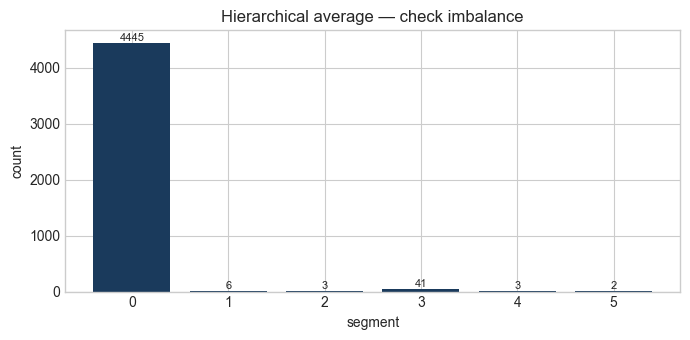

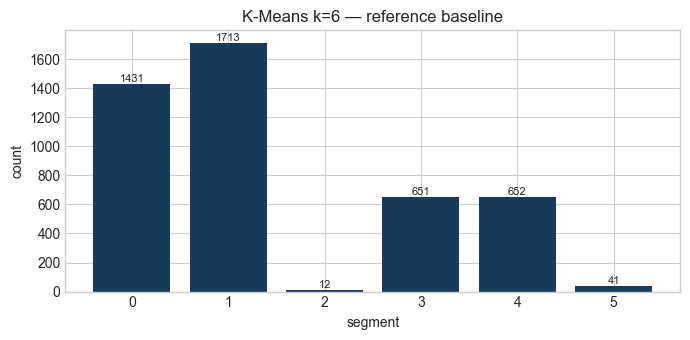

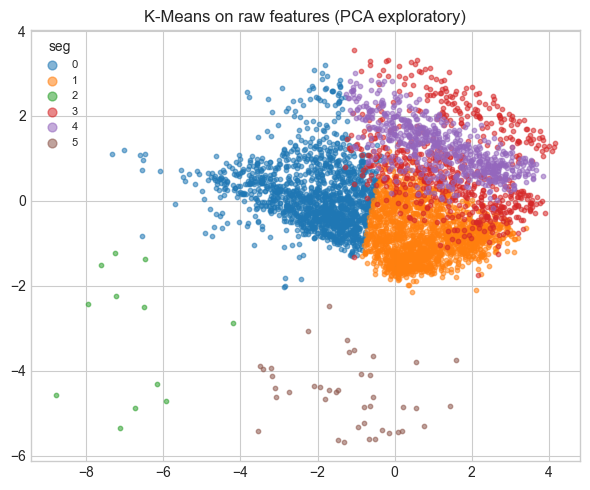

In [5]:
show_sizes(classic_labels["hier_average_k6"], "Hierarchical average — check imbalance")
show_sizes(classic_labels["kmeans_k6"], "K-Means k=6 — reference baseline")
pca_scatter(X, classic_labels["kmeans_k6"], "K-Means on raw features")


### GMM BIC sweep (let the data suggest k)

gmm_bic_k3                   sil= 0.2763  DB= 2.0035  k=3  noise=0.00%


gmm_bic_k4                   sil= 0.2687  DB=    2.1  k=4  noise=0.00%


gmm_bic_k5                   sil= 0.3176  DB= 1.8566  k=5  noise=0.00%


gmm_bic_k6                   sil=  0.307  DB= 2.1859  k=6  noise=0.00%


gmm_bic_k7                   sil= 0.1748  DB= 2.2092  k=7  noise=0.00%


gmm_bic_k8                   sil= 0.1761  DB= 1.8721  k=8  noise=0.00%


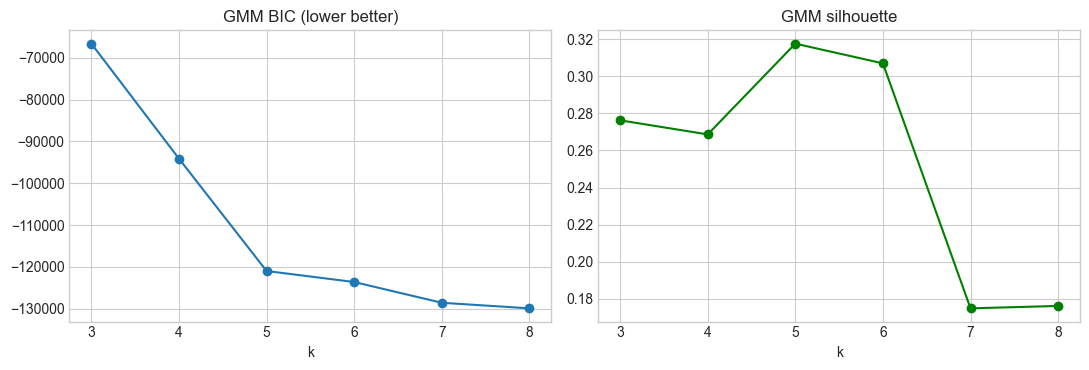

Best BIC k = 8


In [6]:
bic_scores, sil_scores, ks = [], [], list(range(3, 9))
for k in ks:
    gmm = GaussianMixture(
        n_components=k, covariance_type="full", random_state=RANDOM_STATE, n_init=3
    )
    lbl = gmm.fit_predict(X)
    bic_scores.append(gmm.bic(X))
    m = evaluate_clustering(X, lbl, random_state=RANDOM_STATE)
    sil_scores.append(m["silhouette"])
    score(
        f"gmm_bic_k{k}",
        "classical",
        "gmm_bic",
        lbl,
        k=k,
        bic=round(float(gmm.bic(X)), 1),
    )

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(ks, bic_scores, "o-")
ax[0].set_title("GMM BIC (lower better)")
ax[0].set_xlabel("k")
ax[1].plot(ks, sil_scores, "g-o")
ax[1].set_title("GMM silhouette")
ax[1].set_xlabel("k")
plt.tight_layout()
plt.show()
print("Best BIC k =", ks[int(np.argmin(bic_scores))])


## 4. Density-based (HDBSCAN / DBSCAN)

Noise points get label `-1` — useful as a "human review" bucket.


DBSCAN eps heuristic (70th pct of 10-NN distance): 0.453

hdbscan_default              sil= 0.3038  DB= 0.9637  k=6  noise=1.44%


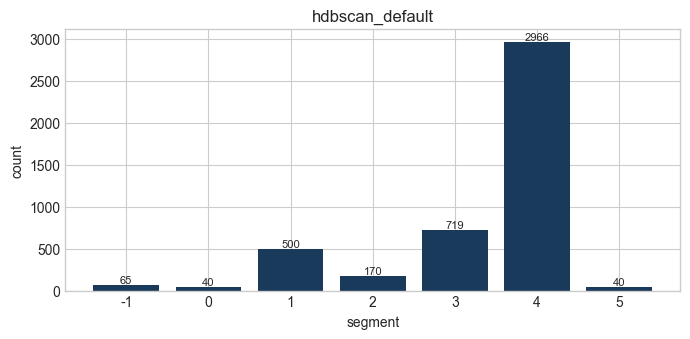

hdbscan_small                sil= 0.3013  DB= 0.9783  k=6  noise=1.16%


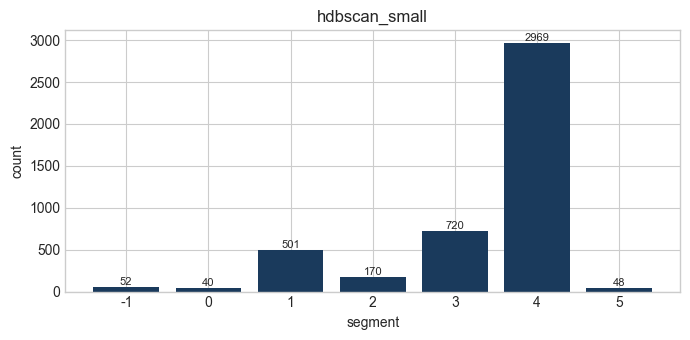

dbscan_eps_auto              sil= 0.2046  DB= 0.8882  k=9  noise=15.73%


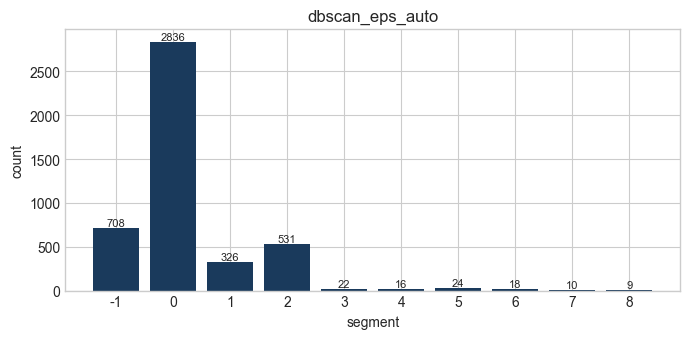

In [7]:
nn = NearestNeighbors(n_neighbors=10).fit(X)
dists, _ = nn.kneighbors(X)
eps_guess = float(np.percentile(dists[:, -1], 70))
print(f"DBSCAN eps heuristic (70th pct of 10-NN distance): {eps_guess:.3f}")

density = {
    "hdbscan_default": HDBSCAN(min_cluster_size=40, min_samples=10),
    "hdbscan_small": HDBSCAN(min_cluster_size=20, min_samples=5),
    "dbscan_eps_auto": DBSCAN(eps=eps_guess, min_samples=10),
}
for run_id, model in density.items():
    lbl = model.fit_predict(X)
    score(run_id, "density", run_id.split("_")[0], lbl)
    show_sizes(lbl, run_id)


## 5. PCA + K-Means (linear representation baseline)

If PCA matches AE quality, the neural net is not buying much.


pca2_kmeans_k6               sil= 0.3578  DB=  0.856  k=6  noise=0.00%


pca4_kmeans_k6               sil= 0.3576  DB= 0.8131  k=6  noise=0.00%


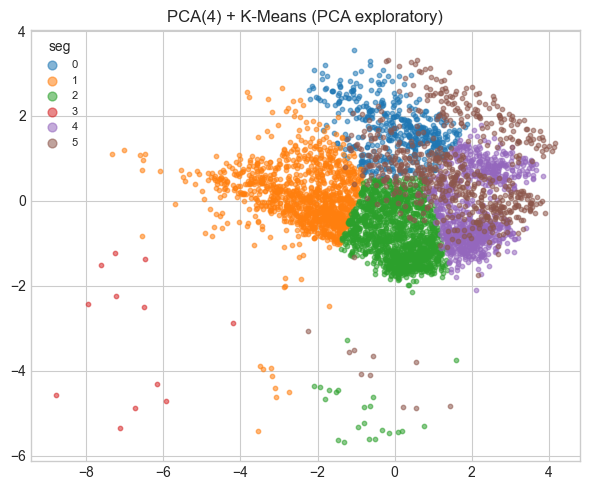

pca8_kmeans_k6               sil=  0.371  DB= 0.8114  k=6  noise=0.00%


In [8]:
for n in (2, 4, 8):
    z = PCA(n_components=n, random_state=RANDOM_STATE).fit_transform(X)
    lbl = KMeans(n_clusters=K_FIXED, n_init=20, random_state=RANDOM_STATE).fit_predict(z)
    score(
        f"pca{n}_kmeans_k6",
        "linear_rep",
        "pca_kmeans",
        lbl,
        space=z,
        k=K_FIXED,
        latent_dim=n,
    )
    if n == 4:
        pca_scatter(z, lbl, "PCA(4) + K-Means")


## 6. Autoencoder exploration

Train several AEs, then cluster each latent with **K-Means, GMM, MiniBatch, HDBSCAN**.


In [9]:
if not TORCH_OK:
    raise ImportError("PyTorch required for AE section")

ae_configs = [
    # name, latent, hidden, noise_std, epochs, note
    ("ae_lat2_h32", 2, 32, 0.0, 40, "very compressed"),
    ("ae_lat4_h32", 4, 32, 0.0, 40, "champion-like latent"),
    ("ae_lat8_h32", 8, 32, 0.0, 40, "wider latent"),
    ("ae_lat16_h32", 16, 32, 0.0, 40, "near-identity risk"),
    ("ae_lat4_h64", 4, 64, 0.0, 40, "more capacity"),
    ("dae_lat4_n01", 4, 32, 0.10, 40, "denoising 0.10"),
    ("dae_lat4_n02", 4, 32, 0.20, 40, "denoising 0.20"),
    ("ae_lat4_long", 4, 32, 0.0, 80, "longer train"),
]

ae_cache = {}
loss_curves = {}

for name, lat, hidden, noise, epochs, note in ae_configs:
    print(f"\n=== Training {name} ({note}) ===")
    ae = train_autoencoder(
        X,
        latent_dim=lat,
        hidden=hidden,
        noise_std=noise,
        epochs=epochs,
        random_state=RANDOM_STATE,
    )
    ae_cache[name] = ae
    loss_curves[name] = ae.losses
    print(f"  final recon loss = {ae.losses[-1]:.5f}")

    heads = {
        "kmeans": KMeans(
            n_clusters=K_FIXED, n_init=20, random_state=RANDOM_STATE
        ).fit_predict(ae.z),
        "gmm": GaussianMixture(
            n_components=K_FIXED,
            covariance_type="full",
            random_state=RANDOM_STATE,
            n_init=3,
        ).fit_predict(ae.z),
        "minibatch": MiniBatchKMeans(
            n_clusters=K_FIXED,
            random_state=RANDOM_STATE,
            batch_size=256,
            n_init=10,
        ).fit_predict(ae.z),
        "hdbscan": HDBSCAN(min_cluster_size=40, min_samples=10).fit_predict(ae.z),
    }
    for head, lbl in heads.items():
        rid = f"{name}_{head}_k{K_FIXED}" if head != "hdbscan" else f"{name}_{head}"
        score(
            rid,
            "autoencoder",
            f"ae_{head}",
            lbl,
            space=ae.z,
            latent_dim=lat,
            hidden=hidden,
            noise_std=noise,
            epochs=epochs,
            recon_loss=round(ae.losses[-1], 5),
            notes=note,
        )



=== Training ae_lat2_h32 (very compressed) ===


  final recon loss = 0.08472


ae_lat2_h32_kmeans_k6        sil= 0.4766  DB= 0.5726  k=6  noise=0.00%


ae_lat2_h32_gmm_k6           sil= 0.4586  DB=  0.803  k=6  noise=0.00%


ae_lat2_h32_minibatch_k6     sil= 0.4158  DB= 0.6962  k=6  noise=0.00%


ae_lat2_h32_hdbscan          sil= 0.4713  DB=  0.643  k=5  noise=1.56%

=== Training ae_lat4_h32 (champion-like latent) ===


... (31 outputs left out)

ae_lat4_long_kmeans_k6       sil= 0.4693  DB= 0.6522  k=6  noise=0.00%


ae_lat4_long_gmm_k6          sil= 0.5188  DB= 1.6038  k=6  noise=0.00%


ae_lat4_long_minibatch_k6    sil= 0.4325  DB= 0.7974  k=6  noise=0.00%


ae_lat4_long_hdbscan         sil= 0.5693  DB= 0.6239  k=4  noise=1.24%


### AE reconstruction loss curves

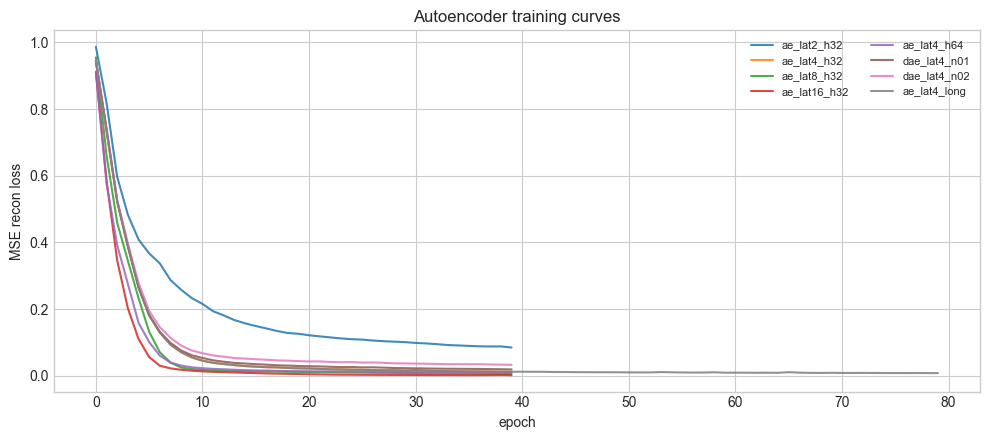

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, losses in loss_curves.items():
    ax.plot(losses, label=name, alpha=0.85)
ax.set_xlabel("epoch")
ax.set_ylabel("MSE recon loss")
ax.set_title("Autoencoder training curves")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()
fig.savefig(OUT / "figures" / "ae_recon_curves_nb.png", dpi=140, bbox_inches="tight")


### Inspect champion-like AE (lat=4) vs stronger encoder (hidden=64)


 ae_lat4_h32


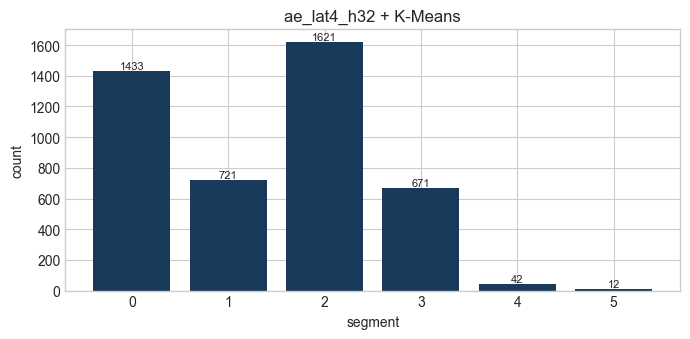

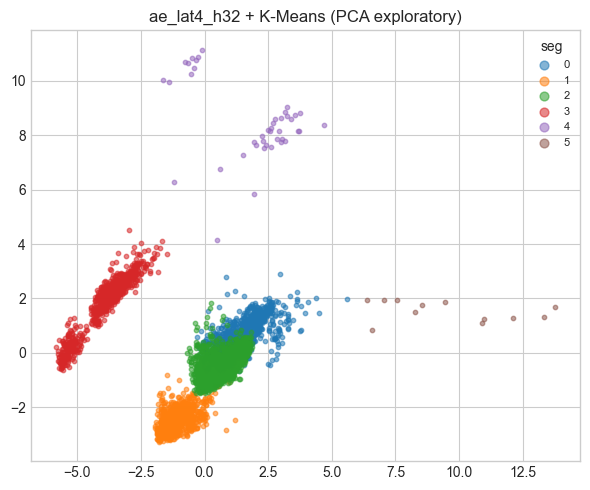

,Transaction_Count,Account_Balance,Total_Credit,Total_Withdrawal,Recency_Days,Account_Age_Days,has_loan,has_card
segment_id,,,,,,,,
0,121.98,31207.44,223734.32,192526.37,2.41,778.53,0.00,0.00
1,242.30,63893.47,1019167.81,955273.39,0.85,1258.38,0.00,1.00
2,313.59,44461.62,827942.14,783479.09,0.34,1646.86,0.00,0.00
3,281.31,51304.46,1192795.55,1141479.67,0.26,1220.84,1.00,0.25
4,224.07,-6305.05,694744.08,701056.31,10.43,1332.40,0.26,0.02
5,27.33,10098.73,33490.42,23491.67,539.17,1379.17,0.00,0.00



 ae_lat4_h64


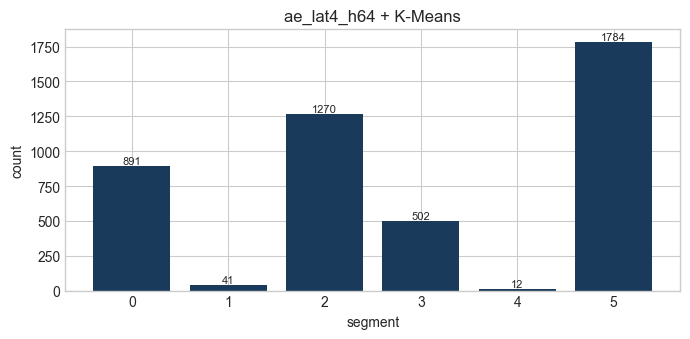

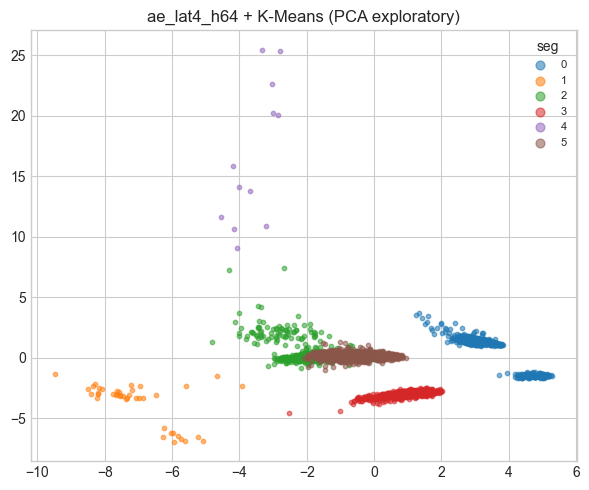

,Transaction_Count,Account_Balance,Total_Credit,Total_Withdrawal,Recency_Days,Account_Age_Days,has_loan,has_card
segment_id,,,,,,,,
0,248.96,63834.07,1092662.70,1028825.41,0.69,1245.80,0.19,1.00
1,226.07,-6468.20,704652.42,711127.99,10.68,1341.20,0.24,0.02
2,115.86,29214.07,200046.04,170831.81,2.67,756.15,0.00,0.00
3,282.41,47045.25,1119346.29,1072290.13,0.35,1229.96,1.00,0.00
4,27.33,10098.73,33490.42,23491.67,539.17,1379.17,0.00,0.00
5,300.44,44669.67,789600.34,744929.10,0.34,1583.46,0.00,0.00



 ae_lat4_long


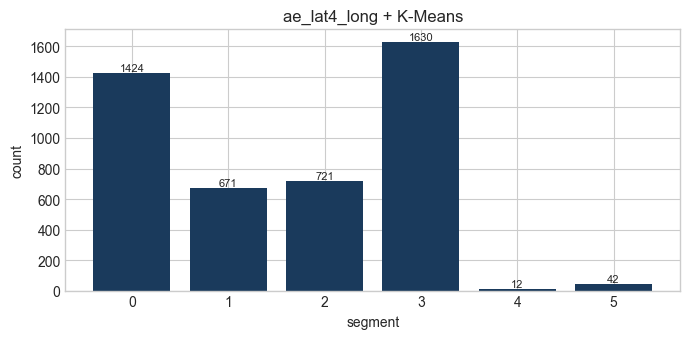

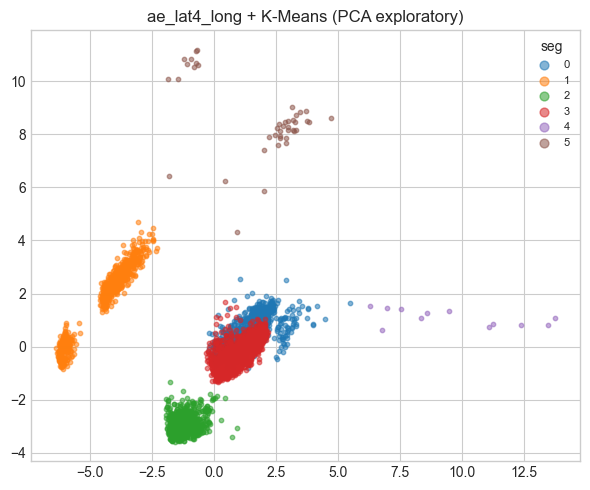

,Transaction_Count,Account_Balance,Total_Credit,Total_Withdrawal,Recency_Days,Account_Age_Days,has_loan,has_card
segment_id,,,,,,,,
0,121.26,31149.16,224103.51,192953.85,2.39,775.51,0.00,0.00
1,281.31,51304.46,1192795.55,1141479.67,0.26,1220.84,1.00,0.25
2,242.30,63893.47,1019167.81,955273.39,0.85,1258.38,0.00,1.00
3,313.16,44439.36,824283.49,779842.71,0.36,1644.71,0.00,0.00
4,27.33,10098.73,33490.42,23491.67,539.17,1379.17,0.00,0.00
5,224.07,-6305.05,694744.08,701056.31,10.43,1332.40,0.26,0.02



 dae_lat4_n01


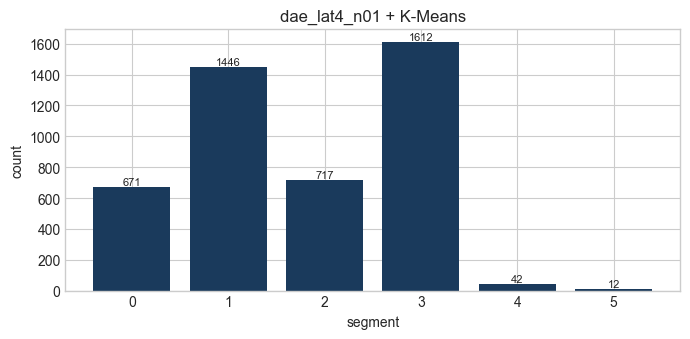

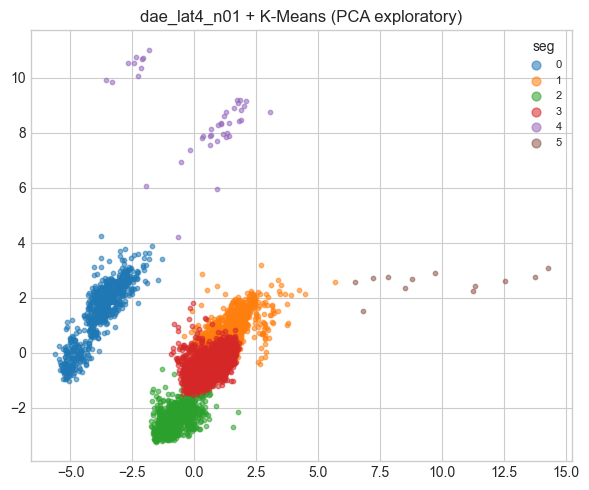

,Transaction_Count,Account_Balance,Total_Credit,Total_Withdrawal,Recency_Days,Account_Age_Days,has_loan,has_card
segment_id,,,,,,,,
0,281.31,51304.46,1192795.55,1141479.67,0.26,1220.84,1.00,0.25
1,121.90,31200.70,226372.96,195171.75,2.43,778.42,0.00,0.00
2,243.47,64086.06,1024342.26,960255.25,0.74,1262.44,0.00,1.00
3,314.51,44537.11,828620.83,784082.29,0.35,1651.20,0.00,0.00
4,224.07,-6305.05,694744.08,701056.31,10.43,1332.40,0.26,0.02
5,27.33,10098.73,33490.42,23491.67,539.17,1379.17,0.00,0.00


In [11]:
for name in ["ae_lat4_h32", "ae_lat4_h64", "ae_lat4_long", "dae_lat4_n01"]:
    z = ae_cache[name].z
    lbl = KMeans(n_clusters=K_FIXED, n_init=20, random_state=RANDOM_STATE).fit_predict(z)
    print("\n", name)
    show_sizes(lbl, f"{name} + K-Means")
    pca_scatter(z, lbl, name + " + K-Means")
    prof = interp.assign(segment_id=lbl).groupby("segment_id")[feat_cols].mean().round(2)
    display(prof)


### AE latent + HDBSCAN (often high silhouette — check noise + k)

view_ae_h64_hdbscan          sil= 0.5753  DB= 0.5742  k=4  noise=1.24%


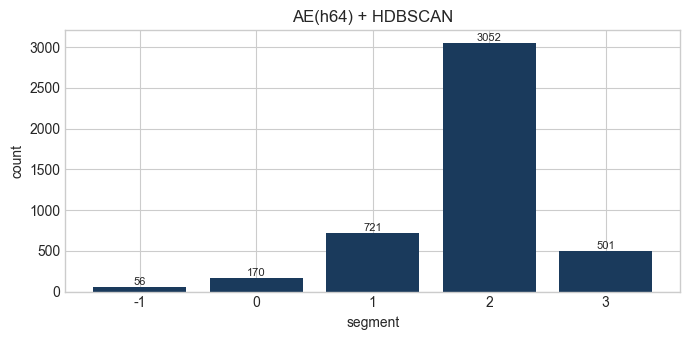

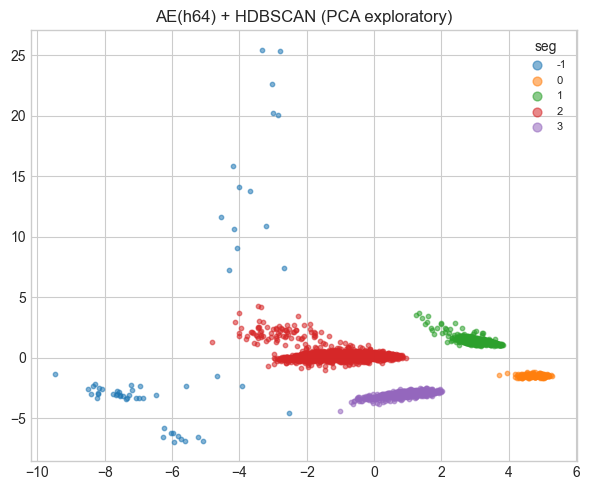

Noise fraction: 0.012444444444444444


,Transaction_Count,Account_Balance,Total_Credit,Total_Withdrawal,Recency_Days,Account_Age_Days,has_loan,has_card
segment_id,,,,,,,,
-1,174.64,-2177.94,530680.33,532885.09,131.27,1318.29,0.2,0.02
0,277.22,63582.11,1404367.51,1340772.50,0.00,1192.46,1.0,1.00
1,242.30,63893.47,1019167.81,955273.39,0.85,1258.38,0.0,1.00
2,223.82,38260.45,544747.22,506485.78,1.17,1239.81,0.0,0.00
3,282.69,47138.39,1121004.67,1073855.35,0.35,1230.48,1.0,0.00


In [12]:
name = "ae_lat4_h64"
z = ae_cache[name].z
lbl = HDBSCAN(min_cluster_size=40, min_samples=10).fit_predict(z)
score("view_ae_h64_hdbscan", "autoencoder", "ae_hdbscan", lbl, space=z)
show_sizes(lbl, "AE(h64) + HDBSCAN")
pca_scatter(z, lbl, "AE(h64) + HDBSCAN")
print("Noise fraction:", (lbl < 0).mean())
prof = interp.assign(segment_id=lbl).groupby("segment_id")[feat_cols].mean().round(2)
display(prof)


## 7. Comparison board

In [13]:
board = pd.DataFrame(rows)
board = board.sort_values("silhouette", ascending=False, na_position="last").reset_index(drop=True)
board_path = OUT / "comparison_board_explore_from_notebook.csv"
board.to_csv(board_path, index=False)

print("TOP 15 by silhouette")
display(board.head(15))

print("\nBest AE + K-Means only")
display(board[board["method"] == "ae_kmeans"].head(10))

print("\nFamily max silhouette")
display(
    board.dropna(subset=["silhouette"])
    .groupby("family")["silhouette"]
    .agg(["count", "max", "mean"])
    .round(4)
    .sort_values("max", ascending=False)
)


TOP 15 by silhouette


,run_id,family,method,k,silhouette,db_index,ch_index,n_clusters,noise_frac,min_frac,max_frac,size_ok,bic,latent_dim,hidden,noise_std,epochs,recon_loss,notes
0,hier_average_k6,classical,hier,6,0.6559,0.4924,253.7,6,0.0000,0.0004,0.9878,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,view_ae_h64_hdbscan,autoencoder,ae_hdbscan,4,0.5753,0.5742,3628.5,4,0.0124,0.0383,0.6868,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ae_lat4_h64_hdbscan,autoencoder,ae_hdbscan,4,0.5753,0.5742,3628.5,4,0.0124,0.0383,0.6868,False,NaN,4.0,64.0,0.0,40.0,0.00987,more capacity
3,ae_lat4_long_hdbscan,autoencoder,ae_hdbscan,4,0.5693,0.6239,4407.1,4,0.0124,0.0383,0.6868,False,NaN,4.0,32.0,0.0,80.0,0.00795,longer train
4,ae_lat4_h64_gmm_k6,autoencoder,ae_gmm,6,0.5346,1.6621,1667.1,6,0.0000,0.0042,0.6453,False,NaN,4.0,64.0,0.0,40.0,0.00987,more capacity
5,ae_lat4_long_gmm_k6,autoencoder,ae_gmm,6,0.5188,1.6038,1867.9,6,0.0000,0.0084,0.6471,False,NaN,4.0,32.0,0.0,80.0,0.00795,longer train
6,ae_lat4_h32_hdbscan,autoencoder,ae_hdbscan,4,0.5066,0.7608,3311.3,4,0.0133,0.0383,0.6867,False,NaN,4.0,32.0,0.0,40.0,0.01200,champion-like latent
7,dae_lat4_n01_hdbscan,autoencoder,ae_hdbscan,4,0.4813,0.8201,2962.3,4,0.0136,0.0383,0.6869,False,NaN,4.0,32.0,0.1,40.0,0.01899,denoising 0.10
8,ae_lat2_h32_kmeans_k6,autoencoder,ae_kmeans,6,0.4766,0.5726,7684.9,6,0.0000,0.0027,0.4509,False,NaN,2.0,32.0,0.0,40.0,0.08472,very compressed
9,ae_lat2_h32_hdbscan,autoencoder,ae_hdbscan,5,0.4713,0.6430,6888.3,5,0.0156,0.0093,0.6804,False,NaN,2.0,32.0,0.0,40.0,0.08472,very compressed



Best AE + K-Means only


,run_id,family,method,k,silhouette,db_index,ch_index,n_clusters,noise_frac,min_frac,max_frac,size_ok,bic,latent_dim,hidden,noise_std,epochs,recon_loss,notes
8,ae_lat2_h32_kmeans_k6,autoencoder,ae_kmeans,6,0.4766,0.5726,7684.9,6,0.0,0.0027,0.4509,False,NaN,2.0,32.0,0.0,40.0,0.08472,very compressed
10,ae_lat4_long_kmeans_k6,autoencoder,ae_kmeans,6,0.4693,0.6522,4037.8,6,0.0,0.0027,0.3622,False,NaN,4.0,32.0,0.0,80.0,0.00795,longer train
11,ae_lat4_h32_kmeans_k6,autoencoder,ae_kmeans,6,0.4640,0.6675,3641.0,6,0.0,0.0027,0.3602,False,NaN,4.0,32.0,0.0,40.0,0.01200,champion-like latent
14,ae_lat4_h64_kmeans_k6,autoencoder,ae_kmeans,6,0.4526,0.6444,3482.7,6,0.0,0.0027,0.3964,False,NaN,4.0,64.0,0.0,40.0,0.00987,more capacity
15,dae_lat4_n01_kmeans_k6,autoencoder,ae_kmeans,6,0.4519,0.6839,3391.8,6,0.0,0.0027,0.3582,False,NaN,4.0,32.0,0.1,40.0,0.01899,denoising 0.10
16,dae_lat4_n02_kmeans_k6,autoencoder,ae_kmeans,6,0.4500,0.6850,3262.5,6,0.0,0.0027,0.3600,False,NaN,4.0,32.0,0.2,40.0,0.03289,denoising 0.20
20,ae_lat8_h32_kmeans_k6,autoencoder,ae_kmeans,6,0.3812,0.8077,2036.7,6,0.0,0.0027,0.3982,False,NaN,8.0,32.0,0.0,40.0,0.00540,wider latent
22,ae_lat16_h32_kmeans_k6,autoencoder,ae_kmeans,6,0.3779,0.8230,2337.8,6,0.0,0.0027,0.3900,False,NaN,16.0,32.0,0.0,40.0,0.00177,near-identity risk



Family max silhouette


,count,max,mean
family,,,
classical,13,0.6559,0.3171
autoencoder,33,0.5753,0.4169
linear_rep,3,0.3710,0.3621
density,3,0.3038,0.2699


### Top silhouette bar chart (read sizes before trusting the leader)

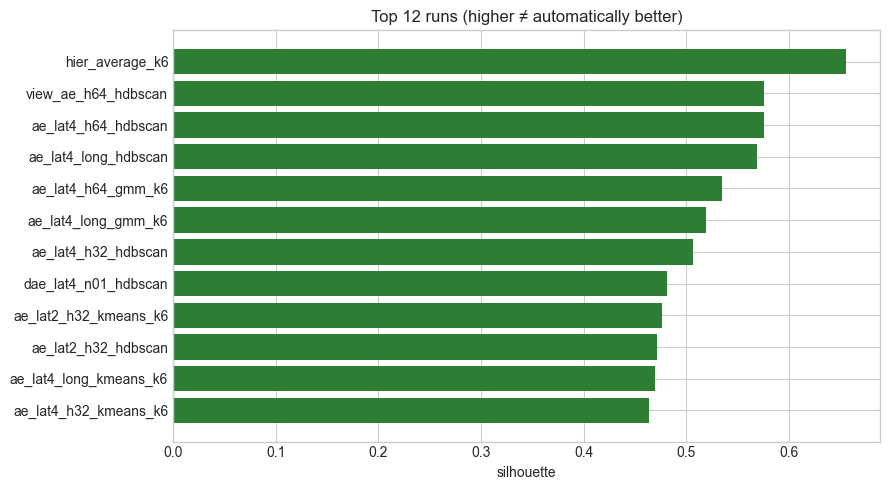

In [14]:
top = board.dropna(subset=["silhouette"]).head(12)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top["run_id"].str[:32][::-1], top["silhouette"][::-1], color="#2E7D32")
ax.set_xlabel("silhouette")
ax.set_title("Top 12 runs (higher ≠ automatically better)")
plt.tight_layout()
plt.show()


## 8. Takeaways

1. **`hier_average`** can top the board and still be useless (one giant cluster).
2. **AE latent ≈ 4** remains the sweet spot; 8/16 overfit/identity.
3. **Wider / longer AE** (`h64`, `long`) helps especially with HDBSCAN/GMM heads.
4. **Denoising AE** is competitive, not clearly better here.
5. **Registered champion AE(lat=4)+K-Means** stays the safe CRM choice (fixed k, stable, interpretable).
6. **v2 candidates:** AE(h64 or long)+K-Means, or AE+HDBSCAN if you accept noise + variable k.

Full write-up: `reports/berka_explore_findings.md`


In [15]:
print("Notebook complete.")
print("Board saved to", board_path)
print("Reference champion: c_ae_lat4_k6 (AE lat4 + KMeans k=6)")


Notebook complete.
Board saved to C:\Users\user\Desktop\gheero\Phase 2\Week 4\banking-customer-segmentation\artifacts\experiments\berka_explore\comparison_board_explore_from_notebook.csv
Reference champion: c_ae_lat4_k6 (AE lat4 + KMeans k=6)
